In [1]:
import scanpy as sc
from banksy.initialize_banksy import initialize_banksy
from banksy.run_banksy import run_banksy_multiparam
from banksy_utils.color_lists import spagcn_color

from sklearn.metrics.cluster import adjusted_rand_score
import numpy as np
import pandas as pd
import seaborn as sns
import os
import torch
import pandas as pd
from sklearn import metrics
import multiprocessing as mp
from sklearn.metrics.cluster import normalized_mutual_info_score

/home/vanhoan310/miniconda3/envs/gnn/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import glob
data_dir_full = []
for data_dir in glob.glob("/data/hoan/spatial_transcriptomics/data/SDMBench/Data/*.h5ad", recursive=True):
    # print(data_dir)
    data_dir_full.append(data_dir)
for data_dir in glob.glob("/data/hoan/spatial_transcriptomics/data/SDMBench/Data/*/*.h5ad", recursive=True):
    if '378k' not in data_dir:
        # print(data_dir)
        data_dir_full.append(data_dir)

In [3]:
# data_dir_full

In [4]:
# for data_dir in data_dir_full:
#     print(data_dir)
#     data_name = data_dir.split('/')[-2]+data_dir.split('/')[-1][:-5]
#     file_pickle = '/data/hoan/spatial_transcriptomics/GraphBGM/Data/Pickle/'+data_name+'.pickle'
#     adata=sc.read_h5ad(data_dir)
#     true_labels = pd.factorize(adata.obs['Region'])[0]

In [5]:
output_folder = '/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/banksy/'

/data/hoan/spatial_transcriptomics/data/SDMBench/Data/osmfish.h5ad
File already exists: /data/hoan/spatial_transcriptomics/GraphBG-analysis/output/banksy/Dataosmfish.csv. Skipping...
/data/hoan/spatial_transcriptomics/data/SDMBench/Data/STARmap_20180505_BY3_1k.h5ad
File already exists: /data/hoan/spatial_transcriptomics/GraphBG-analysis/output/banksy/DataSTARmap_20180505_BY3_1k.csv. Skipping...
/data/hoan/spatial_transcriptomics/data/SDMBench/Data/starmap/20180417_BZ5_control.h5ad
File already exists: /data/hoan/spatial_transcriptomics/GraphBG-analysis/output/banksy/starmap20180417_BZ5_control.csv. Skipping...
/data/hoan/spatial_transcriptomics/data/SDMBench/Data/starmap/20180419_BZ9_control.h5ad
File already exists: /data/hoan/spatial_transcriptomics/GraphBG-analysis/output/banksy/starmap20180419_BZ9_control.csv. Skipping...
/data/hoan/spatial_transcriptomics/data/SDMBench/Data/starmap/20180424_BZ14_control.h5ad
File already exists: /data/hoan/spatial_transcriptomics/GraphBG-analysis/

/home/vanhoan310/miniconda3/envs/gnn/lib/python3.8/site-packages/banksy/main.py:302: RuntimeWarning: invalid value encountered in divide
  zscored_matrix = (matrix - E_x) / np.sqrt(variance)


Shape of BANKSY matrix: (3636, 100614)
Type of banksy_matrix: <class 'anndata._core.anndata.AnnData'>

Current decay types: ['scaled_gaussian']

Reducing dims of dataset in (Index = scaled_gaussian, lambda = 0.8)

Setting the total number of PC = 20
Original shape of matrix: (3636, 100614)
Reduced shape of matrix: (3636, 20)
------------------------------------------------------------
min_value = -88.23007246283132, mean = 9.692772192987066e-17, max = 131.21126516764923

Conducting clustering with Leiden Parition
Decay type: scaled_gaussian
Neighbourhood Contribution (Lambda Parameter): 0.8
reduced_pc_20 

PCA dims to analyse: [20]

Setting up partitioner for (nbr decay = scaled_gaussian), Neighbourhood contribution = 0.8, PCA dimensions = 20)


Nearest-neighbour weighted graph (dtype: float64, shape: (3636, 3636)) has 181800 nonzero entries.
---- Ran find_nn in 0.27 s ----


Nearest-neighbour connectivity graph (dtype: int16, shape: (3636, 3636)) has 181800 nonzero entries.

(after co

,decay,lambda_param,num_pcs,resolution,num_labels,labels,adata,ari
scaled_gaussian_pc20_nc0.80_r1.50,scaled_gaussian,0.8,20,1.505,19,"Label object:\nNumber of labels: 19, number of...",[[[View of AnnData object with n_obs × n_vars ...,0.066109


Anndata AxisArrays with keys: reduced_pc_20
Iteration 1: Resolution = 1.5050 -> Clusters found = 19
Runtime Sep-24-2026-06-34

33538 genes to be analysed:
Gene List:
Index(['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3',
       'AL627309.2', 'AL627309.4', 'AL732372.1', 'OR4F29', 'AC114498.1',
       ...
       'AC007325.2', 'BX072566.1', 'AL354822.1', 'AC023491.2', 'AC004556.1',
       'AC233755.2', 'AC233755.1', 'AC240274.1', 'AC213203.1', 'FAM231C'],
      dtype='object', length=33538)



...

/home/vanhoan310/miniconda3/envs/gnn/lib/python3.8/site-packages/banksy/main.py:302: RuntimeWarning: invalid value encountered in divide
  zscored_matrix = (matrix - E_x) / np.sqrt(variance)


Shape of BANKSY matrix: (3636, 100614)
Type of banksy_matrix: <class 'anndata._core.anndata.AnnData'>

Current decay types: ['scaled_gaussian']

Reducing dims of dataset in (Index = scaled_gaussian, lambda = 0.8)

Setting the total number of PC = 20
Original shape of matrix: (3636, 100614)
Reduced shape of matrix: (3636, 20)
------------------------------------------------------------
min_value = -88.23007246282543, mean = 5.0027211318642916e-17, max = 131.21126516751266

Conducting clustering with Leiden Parition
Decay type: scaled_gaussian
Neighbourhood Contribution (Lambda Parameter): 0.8
reduced_pc_20 

PCA dims to analyse: [20]

Setting up partitioner for (nbr decay = scaled_gaussian), Neighbourhood contribution = 0.8, PCA dimensions = 20)


Nearest-neighbour weighted graph (dtype: float64, shape: (3636, 3636)) has 181800 nonzero entries.
---- Ran find_nn in 0.47 s ----


Nearest-neighbour connectivity graph (dtype: int16, shape: (3636, 3636)) has 181800 nonzero entries.

(after c

,decay,lambda_param,num_pcs,resolution,num_labels,labels,adata,ari
scaled_gaussian_pc20_nc0.80_r0.15,scaled_gaussian,0.8,20,0.150156,5,"Label object:\nNumber of labels: 5, number of ...",[[[View of AnnData object with n_obs × n_vars ...,0.160197


Anndata AxisArrays with keys: reduced_pc_20
Iteration 6: Resolution = 0.1502 -> Clusters found = 5
Exact cluster match achieved!
NMI =  0.37658076928008183
5 5


/home/vanhoan310/miniconda3/envs/gnn/lib/python3.8/site-packages/banksy/run_banksy.py:141: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(adata_temp.obs[coord_keys[0]].values,


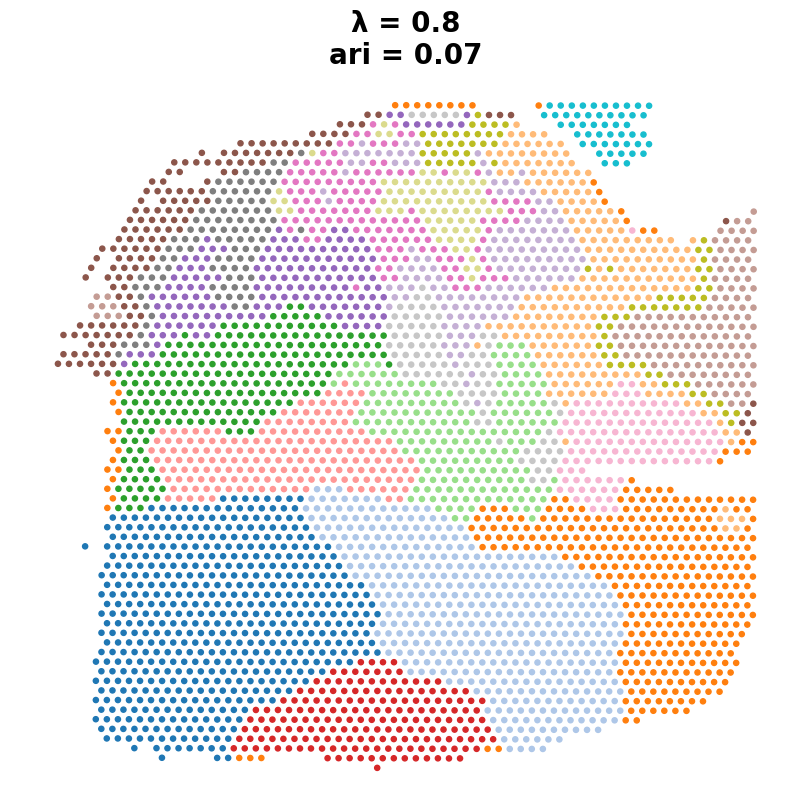

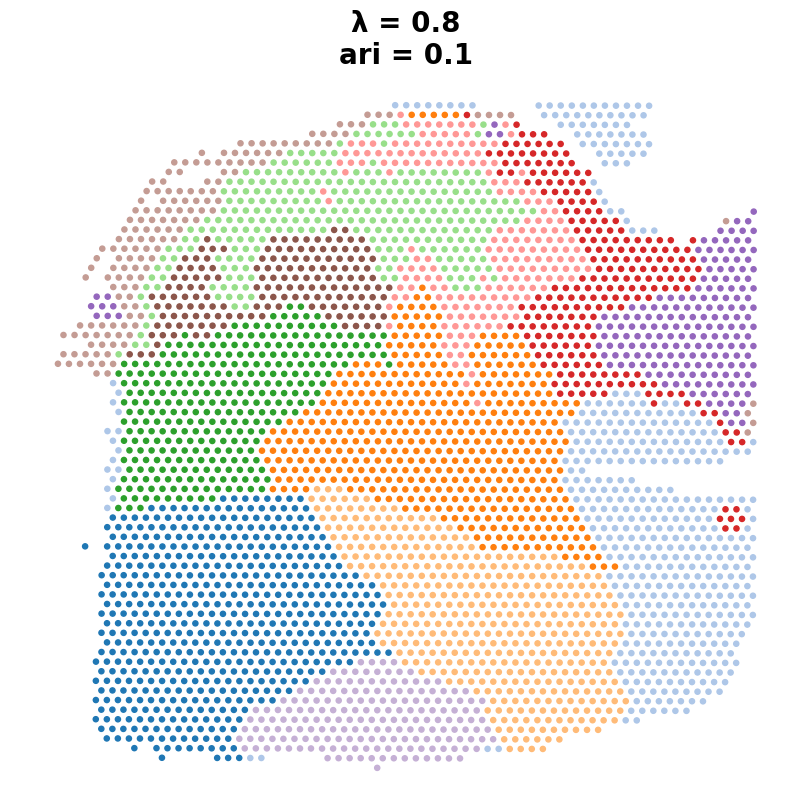

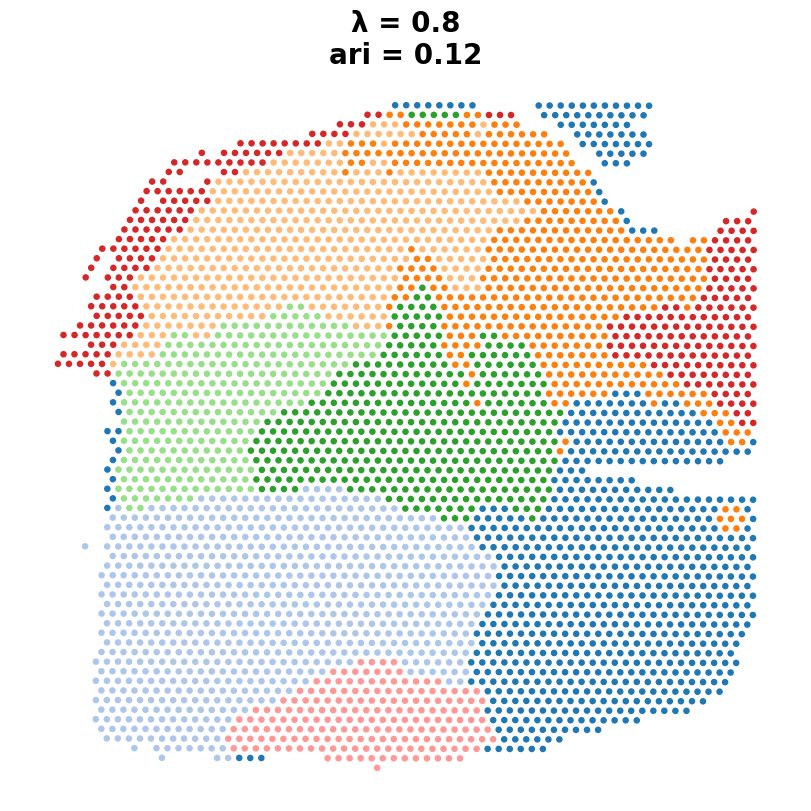

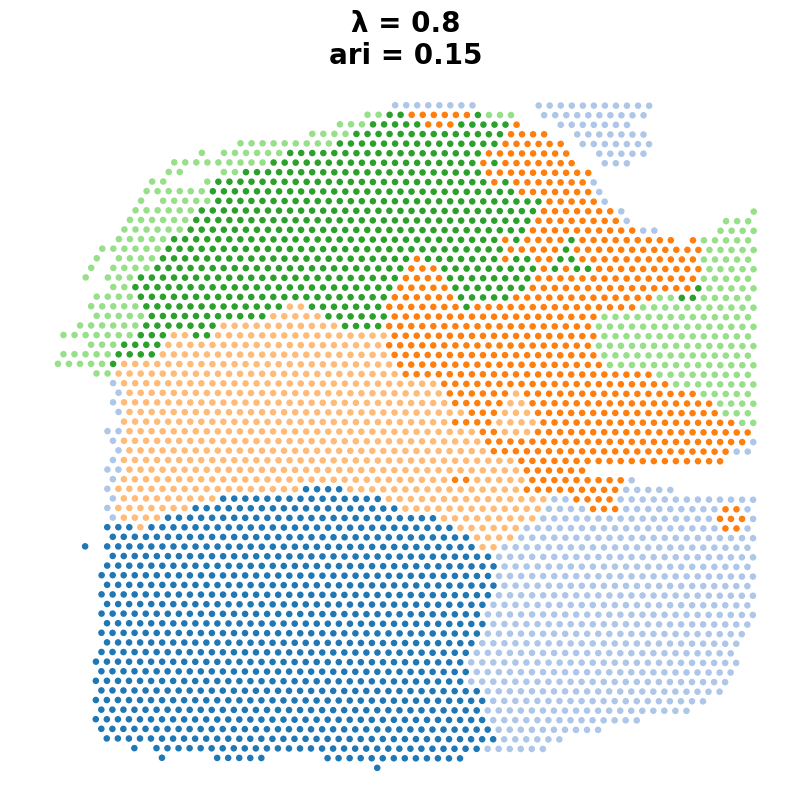

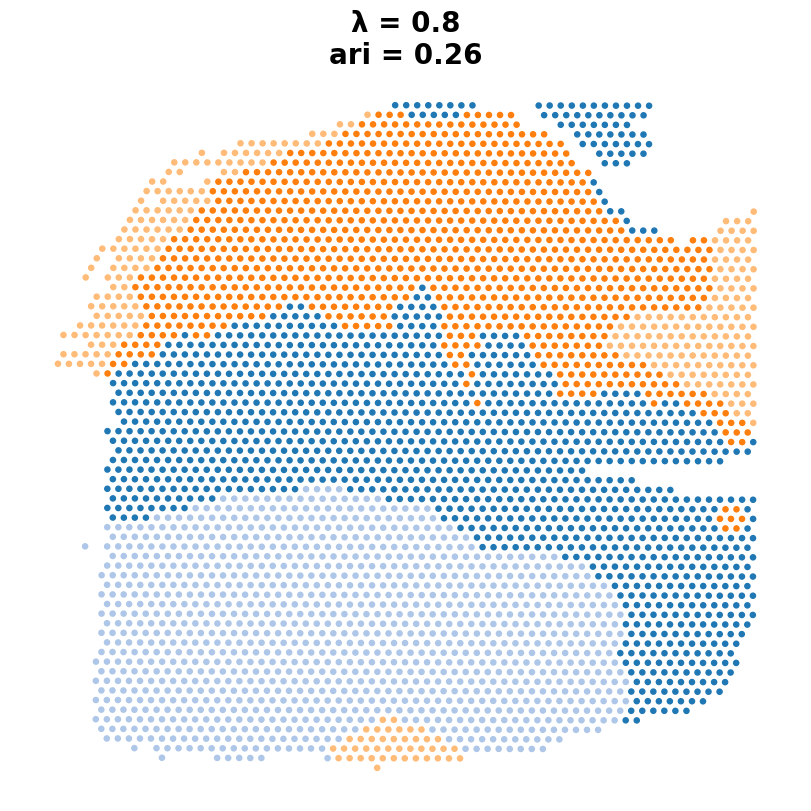

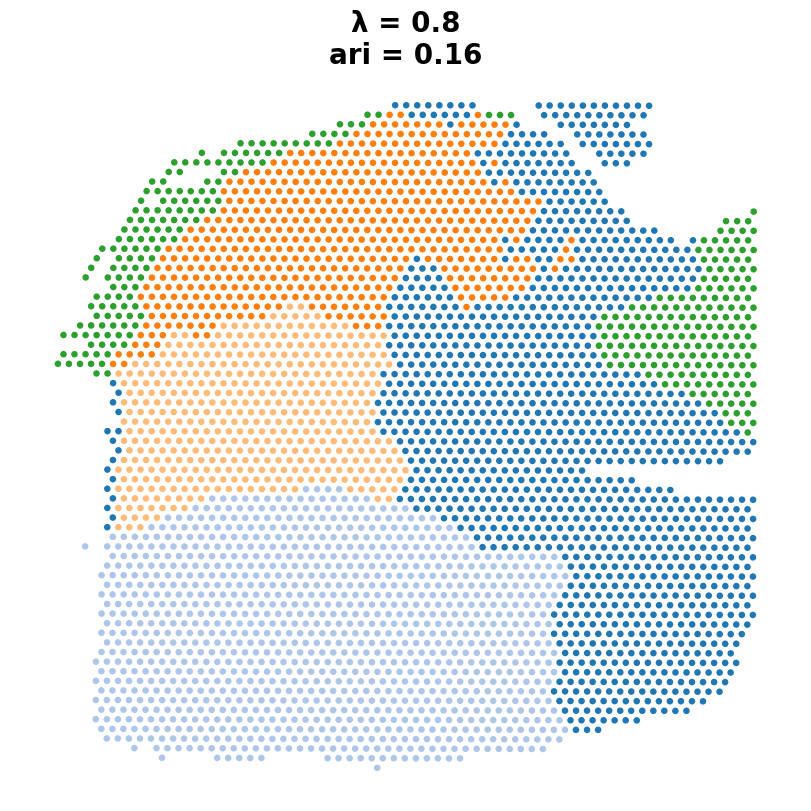

In [6]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.metrics import normalized_mutual_info_score

for data_dir in data_dir_full:
    print(data_dir)
    data_name = data_dir.split('/')[-2] + data_dir.split('/')[-1][:-5]
    out_data = output_folder + data_name + '.csv'

    # --- Check if out_data file exists ---
    if os.path.exists(out_data):
        print(f"File already exists: {out_data}. Skipping...")
    else:
        print(f"File not found. Proceeding with analysis: {out_data}")
        file_pickle = '/data/hoan/spatial_transcriptomics/GraphBGM/Data/Pickle/' + data_name + '.pickle'
        
        # Load and filter out NaN labels
        adata = sc.read_h5ad(data_dir)
        adata = adata[~adata.obs['Region'].isna()].copy()
        
        true_labels = pd.factorize(adata.obs['Region'])[0]
        adata.obs['x'] = adata.obsm['spatial'][:, 0]
        adata.obs['y'] = adata.obsm['spatial'][:, 1]
        
        coord_keys = ('x', 'y', 'spatial')
        pca_dims = [20] # number of dimensions to keep after PCA
        lambda_list = [.8] # lambda
        k_geom = 15 # spatial neighbours
        max_m = 1 # use AGF
        nbr_weight_decay = "scaled_gaussian" # can also be "reciprocal", "uniform" or "ranked"
        
        banksy_dict = initialize_banksy(
            adata,
            coord_keys,
            k_geom,
            nbr_weight_decay=nbr_weight_decay,
            max_m=max_m,
            plt_edge_hist=False,
            plt_nbr_weights=False,
            plt_agf_angles=False,
            plt_theta=False,
        )
        
        annotation_key = 'Region' # Key to access annotations in adata.obs[annotation_keys]
        num_clusters = len(set(true_labels))
        cluster_algorithm = 'leiden' 
        
        # --- Binary Search for Resolution ---
        low_res = 0.01
        high_res = 3.0
        best_res = 0.8
        best_labels = None
        max_iterations = 10
        
        print(f"Target number of clusters: {num_clusters}")
        
        for iteration in range(max_iterations):
            mid_res = (low_res + high_res) / 2.0
            resolutions = [mid_res]
            
            # Dynamically generate a large enough color list using mcolors
            dynamic_color_list = [plt.cm.tab20(i % 20) for i in range(100)]
            dynamic_color_list = [mcolors.to_hex(c) for c in dynamic_color_list]
            
            results_df = run_banksy_multiparam(
                adata,
                banksy_dict,
                lambda_list,
                resolutions,
                color_list=dynamic_color_list,
                max_m=max_m,
                filepath=output_folder,
                key=coord_keys,
                pca_dims=pca_dims,
                annotation_key=annotation_key,
                max_labels=num_clusters,
                cluster_algorithm=cluster_algorithm,
                match_labels=False,
                savefig=False,
                add_nonspatial=False,
                variance_balance=False,
            )
            
            params_name = results_df.index[0]
            tmp_label = results_df.loc[params_name, "labels"].dense
            n_clusters_found = len(np.unique(tmp_label))
            
            print(f"Iteration {iteration+1}: Resolution = {mid_res:.4f} -> Clusters found = {n_clusters_found}")
            
            best_res = mid_res
            best_labels = tmp_label
            
            if n_clusters_found == num_clusters:
                print("Exact cluster match achieved!")
                break
            elif n_clusters_found < num_clusters:
                low_res = mid_res
            else:
                high_res = mid_res
        
        # Final evaluation using the best found labels
        tmp_label = best_labels
        print("NMI = ", normalized_mutual_info_score(tmp_label, true_labels))
        print(num_clusters, len(np.unique(tmp_label)))
        print('=='*15)
        
        df_out = pd.DataFrame({'ground_truth': true_labels, 'BANKSY': tmp_label})
        df_out.to_csv(out_data, index=False)

        break;

In [7]:
print('Hi')

Hi
